# AI-Based Text and Visual Recognition System

## Project Overview
This project combines Natural Language Processing and Computer Vision to perform text classification, object detection, and facial landmark detection using Python and deep learning technologies.

## Objectives
- Classify text into positive and negative sentiment categories.
- Detect and identify objects in images.
- Identify facial landmarks such as eyes, nose, and lips.

## Technologies Used
- Python
- TensorFlow
- TensorFlow Hub
- Natural Language Processing
- OpenCV
- MediaPipe
- Google Colab

## Project Modules
1. Text Classification
2. Object Detection
3. Facial Landmark Detection

In [1]:
!pip install -q tensorflow tensorflow-hub mediapipe opencv-python-headless matplotlib pillow

In [2]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import matplotlib.pyplot as plt
import cv2
import mediapipe as mp
import requests
import re
import os

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from google.colab import files
from PIL import Image

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


All libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000


In [4]:
x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size, 32),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.6454 - loss: 0.6853 - val_accuracy: 0.6744 - val_loss: 0.6690
Epoch 2/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7046 - loss: 0.6429 - val_accuracy: 0.7196 - val_loss: 0.6055
Epoch 3/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7783 - loss: 0.5553 - val_accuracy: 0.8084 - val_loss: 0.5076


In [7]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7985 - loss: 0.5156
Test Accuracy: 79.85 %


In [8]:
word_index = imdb.get_word_index()

def classify_text(text):
    words = text.lower().split()
    sequence = []

    for word in words:
        index = word_index.get(word)

        if index is None or index + 3 >= vocab_size:
            sequence.append(2)
        else:
            sequence.append(index + 3)

    sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    if prediction >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Input:", text)
    print("Predicted sentiment:", sentiment)
    print("Prediction score:", round(float(prediction), 4))

classify_text("This movie was wonderful and amazing")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Input: This movie was wonderful and amazing
Predicted sentiment: Positive
Prediction score: 0.5174


In [9]:
classify_text("This movie was boring and disappointing")

Input: This movie was boring and disappointing
Predicted sentiment: Negative
Prediction score: 0.4422


In [10]:
detector = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
)

print("Object detection model loaded successfully!")

Object detection model loaded successfully!


In [11]:
url = "https://raw.githubusercontent.com/tensorflow/models/master/research/object_detection/data/mscoco_label_map.pbtxt"

response = requests.get(url)
response.raise_for_status()

label_map = {}

for item in re.findall(r'item\s*\{([^}]*)\}', response.text, re.S):
    id_match = re.search(r'id:\s*(\d+)', item)
    name_match = re.search(r'display_name:\s*"([^"]+)"', item)

    if id_match and name_match:
        label_map[int(id_match.group(1))] = name_match.group(1)

print("Number of labels loaded:", len(label_map))

Number of labels loaded: 80


Saving photo.jpg to photo.jpg
Image uploaded successfully!
Image name: photo.jpg


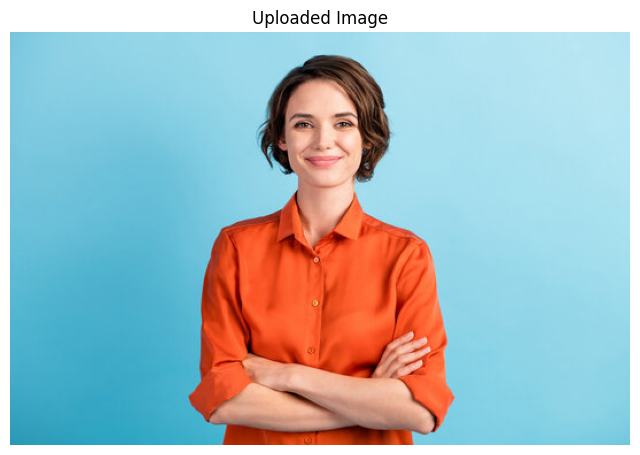

In [12]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")
image_array = np.array(image)

print("Image uploaded successfully!")
print("Image name:", image_path)

plt.figure(figsize=(8, 6))
plt.imshow(image_array)
plt.axis("off")
plt.title("Uploaded Image")
plt.show()

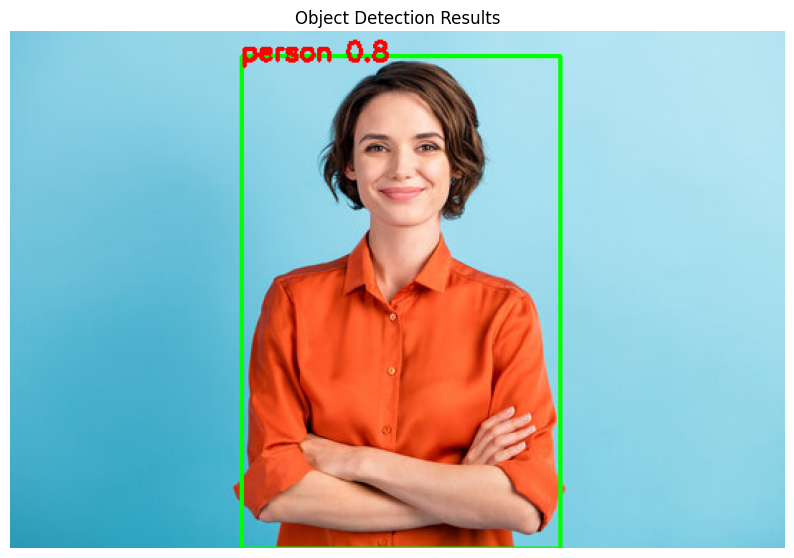

In [13]:
image_tensor = tf.convert_to_tensor(
    image_array,
    dtype=tf.uint8
)

image_tensor = image_tensor[tf.newaxis, ...]

detections = detector(image_tensor)

boxes = detections["detection_boxes"].numpy()[0]
classes = detections["detection_classes"].numpy()[0].astype(int)
scores = detections["detection_scores"].numpy()[0]

height, width = image_array.shape[:2]
output_image = image_array.copy()

for box, class_id, score in zip(boxes, classes, scores):
    if score > 0.5:
        ymin, xmin, ymax, xmax = box

        x1 = int(xmin * width)
        y1 = int(ymin * height)
        x2 = int(xmax * width)
        y2 = int(ymax * height)

        label = label_map.get(class_id, "Unknown")

        cv2.rectangle(
            output_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output_image,
            label + " " + str(round(float(score), 2)),
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

plt.figure(figsize=(10, 7))
plt.imshow(output_image)
plt.axis("off")
plt.title("Object Detection Results")
plt.show()

In [14]:
Image.fromarray(output_image).save("object_detection_result.png")

print("Object detection result saved successfully!")

Object detection result saved successfully!


In [15]:
mp_face_mesh = mp.solutions.face_mesh
mp_drawing = mp.solutions.drawing_utils
mp_styles = mp.solutions.drawing_styles

face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=5,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

print("Facial landmark detection initialized!")

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [16]:
!pip uninstall -y mediapipe
!pip install mediapipe==0.10.21

Found existing installation: mediapipe 1.2.3
Uninstalling mediapipe-1.2.3:
  Successfully uninstalled mediapipe-1.2.3
ERROR: Could not find a version that satisfies the requirement mediapipe==0.10.21 (from versions: 0.10.30, 0.10.31, 0.10.32, 0.10.33, 0.10.35, 1.0.0, 1.0.1, 1.1.0, 1.1.1, 1.2.0, 1.2.2, 1.2.3)
ERROR: No matching distribution found for mediapipe==0.10.21


In [17]:
!pip install mediapipe==0.10.35

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 46.2 MB/s  0:00:00


In [1]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("Solutions available:", hasattr(mp, "solutions"))

MediaPipe version: 0.10.35
Solutions available: False


In [2]:
!pip install -q mediapipe opencv-python-headless

In [3]:
!wget -q https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task -O face_landmarker.task

print("Face landmark model downloaded!")

Face landmark model downloaded!


In [4]:
import mediapipe as mp
import cv2
import numpy as np
import matplotlib.pyplot as plt

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="face_landmarker.task"
    ),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=5
)

face_landmarker = FaceLandmarker.create_from_options(options)

print("Facial landmark detection initialized successfully!")

Facial landmark detection initialized successfully!


Saving picture.jpg to picture.jpg


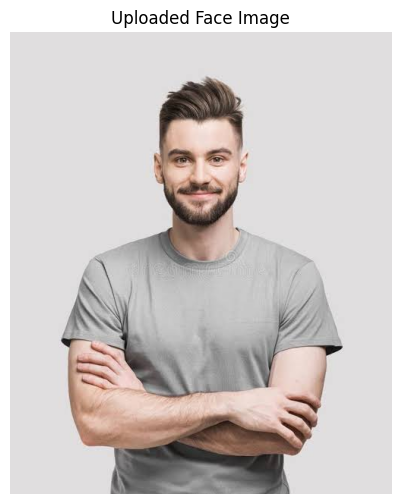

In [5]:
from google.colab import files

uploaded_face = files.upload()
face_path = next(iter(uploaded_face))

face_image = cv2.imread(face_path)
face_rgb = cv2.cvtColor(face_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 6))
plt.imshow(face_rgb)
plt.axis("off")
plt.title("Uploaded Face Image")
plt.show()

Facial landmarks detected successfully!


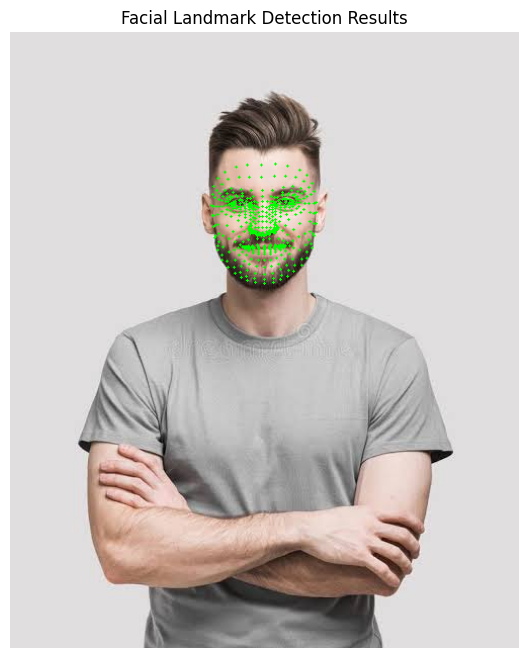

In [6]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=face_rgb
)

results = face_landmarker.detect(mp_image)

landmark_image = face_rgb.copy()

height, width = landmark_image.shape[:2]

if results.face_landmarks:
    for face_landmarks in results.face_landmarks:
        for landmark in face_landmarks:
            x = int(landmark.x * width)
            y = int(landmark.y * height)

            cv2.circle(
                landmark_image,
                (x, y),
                1,
                (0, 255, 0),
                -1
            )

    print("Facial landmarks detected successfully!")

else:
    print("No face detected. Please upload another image.")

plt.figure(figsize=(10, 8))
plt.imshow(landmark_image)
plt.axis("off")
plt.title("Facial Landmark Detection Results")
plt.show()

In [7]:
Image.fromarray(landmark_image).save("landmark_detection_result.png")

print("Facial landmark result saved successfully!")

NameError: name 'Image' is not defined

In [8]:
from PIL import Image

Image.fromarray(landmark_image).save("landmark_detection_result.png")

print("Facial landmark result saved successfully!")

Facial landmark result saved successfully!


In [9]:
model.save("text_classification_model.keras")

print("Text classification model saved successfully!")

NameError: name 'model' is not defined

In [10]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=512,
    validation_split=0.2
)

NameError: name 'model' is not defined

In [11]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [12]:
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 25000
Testing samples: 25000


In [13]:
x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [14]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size, 32),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.6109 - loss: 0.6850 - val_accuracy: 0.7112 - val_loss: 0.6674
Epoch 2/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7226 - loss: 0.6402 - val_accuracy: 0.7546 - val_loss: 0.6004
Epoch 3/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7894 - loss: 0.5500 - val_accuracy: 0.8130 - val_loss: 0.5013


In [16]:
model.save("text_classification_model.keras")

print("Text classification model saved successfully!")

Text classification model saved successfully!


In [17]:
from PIL import Image

Image.fromarray(output_image).save("object_detection_result.png")
Image.fromarray(landmark_image).save("landmark_detection_result.png")

print("Both output images saved successfully!")

NameError: name 'output_image' is not defined

In [18]:
print("Image available:", "image_array" in globals())
print("Detector available:", "detector" in globals())
print("Labels available:", "label_map" in globals())

Image available: False
Detector available: False
Labels available: False


In [19]:
image_tensor = tf.convert_to_tensor(image_array, dtype=tf.uint8)
image_tensor = image_tensor[tf.newaxis, ...]

detections = detector(image_tensor)

boxes = detections["detection_boxes"].numpy()[0]
classes = detections["detection_classes"].numpy()[0].astype(int)
scores = detections["detection_scores"].numpy()[0]

height, width = image_array.shape[:2]
output_image = image_array.copy()

for box, class_id, score in zip(boxes, classes, scores):
    if score > 0.5:
        ymin, xmin, ymax, xmax = box

        x1 = int(xmin * width)
        y1 = int(ymin * height)
        x2 = int(xmax * width)
        y2 = int(ymax * height)

        label = label_map.get(class_id, "Unknown")

        cv2.rectangle(output_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        cv2.putText(
            output_image,
            label + " " + str(round(float(score), 2)),
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

plt.figure(figsize=(10, 7))
plt.imshow(output_image)
plt.axis("off")
plt.title("Object Detection Results")
plt.show()

NameError: name 'image_array' is not defined

Saving photo.jpg to photo (1).jpg
Image uploaded successfully: photo (1).jpg


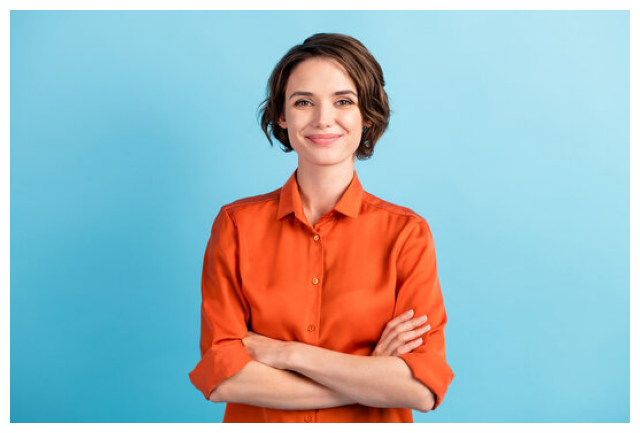

In [20]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")
image_array = np.array(image)

print("Image uploaded successfully:", image_path)

plt.figure(figsize=(8, 6))
plt.imshow(image_array)
plt.axis("off")
plt.show()

In [21]:
print("TensorFlow:", "tf" in globals())
print("Detector:", "detector" in globals())
print("Labels:", "label_map" in globals())
print("Image:", "image_array" in globals())

TensorFlow: True
Detector: False
Labels: False
Image: True


In [22]:
import tensorflow_hub as hub

detector = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
)

print("Object detection model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Object detection model loaded successfully!


In [23]:
import requests
import re

url = "https://raw.githubusercontent.com/tensorflow/models/master/research/object_detection/data/mscoco_label_map.pbtxt"

response = requests.get(url)
response.raise_for_status()

label_map = {}

for item in re.findall(r'item\s*\{([^}]*)\}', response.text, re.S):
    id_match = re.search(r'id:\s*(\d+)', item)
    name_match = re.search(r'display_name:\s*"([^"]+)"', item)

    if id_match and name_match:
        label_map[int(id_match.group(1))] = name_match.group(1)

print("Number of labels loaded:", len(label_map))

Number of labels loaded: 80


In [24]:
print("TensorFlow:", "tf" in globals())
print("Detector:", "detector" in globals())
print("Labels:", "label_map" in globals())
print("Image:", "image_array" in globals())

TensorFlow: True
Detector: True
Labels: True
Image: True


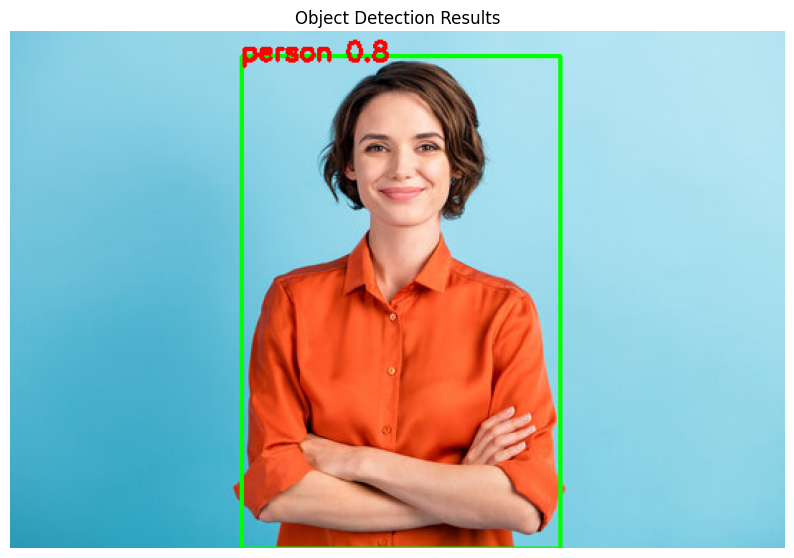

In [25]:
image_tensor = tf.convert_to_tensor(
    image_array,
    dtype=tf.uint8
)

image_tensor = image_tensor[tf.newaxis, ...]

detections = detector(image_tensor)

boxes = detections["detection_boxes"].numpy()[0]
classes = detections["detection_classes"].numpy()[0].astype(int)
scores = detections["detection_scores"].numpy()[0]

height, width = image_array.shape[:2]
output_image = image_array.copy()

for box, class_id, score in zip(boxes, classes, scores):
    if score > 0.5:
        ymin, xmin, ymax, xmax = box

        x1 = int(xmin * width)
        y1 = int(ymin * height)
        x2 = int(xmax * width)
        y2 = int(ymax * height)

        label = label_map.get(class_id, "Unknown")

        cv2.rectangle(
            output_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output_image,
            label + " " + str(round(float(score), 2)),
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

plt.figure(figsize=(10, 7))
plt.imshow(output_image)
plt.axis("off")
plt.title("Object Detection Results")
plt.show()

In [26]:
from PIL import Image

Image.fromarray(output_image).save("object_detection_result.png")
Image.fromarray(landmark_image).save("landmark_detection_result.png")

print("Both output images saved successfully!")

Both output images saved successfully!


In [27]:
from google.colab import files

files.download("text_classification_model.keras")
files.download("object_detection_result.png")
files.download("landmark_detection_result.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>